# Water Loss Analytics
## 05 — Modeling dan Evaluasi
**Raden Satrio Hibatull Rasendriyo**

Saya menguji apakah model dapat memperkirakan kehilangan air fisik tahun berikutnya lebih baik daripada memakai nilai tahun sebelumnya. Data dan delapan fitur mengikuti notebook 04; saya tidak mengubah cakupan data berdasarkan hasil test.

Alur proyek: data understanding → cleaning → SQL dan EDA → persiapan ML → modeling dan evaluasi → pembaruan dashboard → PPT.

Bagian analisis menjelaskan pola historis. Bagian ML menguji manfaat prediksi secara terpisah. Model yang lebih kompleks belum tentu lebih baik daripada baseline.


### 1. Rancangan eksperimen
- **Training:** tahun target 2017–2021, 1.850 sampel pada snapshot proyek.
- **Validation:** tahun target 2022–2023, 737 sampel.
- **Test:** tahun target 2024, 307 sampel.
- **Baseline persistence:** prediksi sama dengan kehilangan fisik tahun sebelumnya.
- **Model:** Ridge dengan scaling dalam pipeline; Random Forest tanpa scaling.
- **Pemilihan:** MAE validation gabungan paling rendah di antara kandidat ML. Jika MAE sama, RMSE lalu nama model menjadi penentu urutan. Perbandingan dengan baseline dicatat terpisah.
- **Evaluasi akhir:** latih ulang kandidat ML terpilih pada training + validation, lalu bandingkan dengan baseline pada test. Tidak mengganti kandidat berdasarkan test.

Enam konfigurasi kandidat ditetapkan pada awal eksperimen. Ini pencarian terbatas, bukan pembuktian bahwa model tersebut optimal. Saya tidak menambah konfigurasi setelah melihat test untuk mengejar hasil yang lebih bagus.

MAE dan RMSE dinyatakan dalam **acre-feet (AF)**. MAE memberi ukuran kesalahan absolut rata-rata; RMSE lebih sensitif terhadap kesalahan besar. R² disertakan sebagai pelengkap dan bukan persentase akurasi. MAPE tidak dipakai karena kehilangan fisik dapat bernilai nol atau sangat kecil.

Prediksi negatif dipotong menjadi nol untuk semua kandidat sebelum penilaian, karena target berupa volume nonnegatif. Jumlah prediksi yang dipotong dicatat. Aturan ini ditetapkan sebelum evaluasi.


### Cara menjalankan
Simpan di `water_loss_analytics/notebooks/`, jalankan notebook 04 terlebih dahulu, kemudian klik **Run All**. Notebook ini membaca `data/ml/ml_config.json` dan tiga CSV split.

Paket: pandas, numpy, scikit-learn, matplotlib, joblib, dan IPython. Jika ada paket yang belum tersedia, jalankan `%pip install scikit-learn matplotlib joblib pandas numpy ipython` pada sel tambahan, lalu restart kernel. Untuk menyamakan versi scikit-learn dengan pengujian pembuat notebook, gunakan `scikit-learn==1.8.0`.

Hasil otomatis disimpan di `outputs/modeling/` dan `models/`. Menjalankan ulang memperbarui file hasil yang sama. Pengulangan untuk memastikan reproduksibilitas tidak menjadikan test sebagai data validation; jangan mengubah pilihan eksperimen setelah membaca hasil test.


In [1]:
from pathlib import Path
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

cwd=Path.cwd().resolve()
candidates=[]
for base in [cwd,*cwd.parents]:
    candidates.extend([base,base/'water_loss_analytics',base/'02_Projects/water_loss_analytics'])
ROOT=next((p for p in candidates if (p/'data/ml/ml_config.json').is_file()),None)
if ROOT is None:
    raise FileNotFoundError('Jalankan notebook 04 dahulu; data/ml/ml_config.json belum ditemukan.')
ml_dir=ROOT/'data/ml'
config=json.loads((ml_dir/'ml_config.json').read_text(encoding='utf-8'))
FEATURES=config['features']; TARGET=config['target']; BASELINE=config['baseline_feature']
assert TARGET not in FEATURES and BASELINE in FEATURES
assert all(f.endswith('_t') for f in FEATURES)
assert config['train_target_years']==list(range(2017,2022))
assert config['validation_target_years']==[2022,2023]
assert config['test_target_years']==[2024]
source_path=ROOT/config['input_file']
if hashlib.sha256(source_path.read_bytes()).hexdigest()!=config['input_sha256']:
    raise ValueError('Input cleaning berubah sejak notebook 04. Jalankan ulang notebook 04 sebelum modeling.')

# Test baru dibaca setelah kandidat dipilih.
def read_part(name):
    part=pd.read_csv(ml_dir/f'water_loss_{name}.csv',encoding='utf-8-sig',dtype={'system_key':'string'})
    years=config[{'train':'train_target_years','validation':'validation_target_years','test':'test_target_years'}[name]]
    assert not part.empty and part['split'].eq(name).all()
    assert set(part.target_year)==set(years)
    assert part.target_year.sub(part.feature_year).eq(1).all()
    assert not part.duplicated(['system_key','target_year']).any()
    assert np.isfinite(part[FEATURES+[TARGET]].to_numpy(dtype=float)).all()
    assert part[TARGET].ge(0).all()
    assert len(part)==config['samples'][name]
    return part
train=read_part('train'); validation=read_part('validation')
assert train.target_year.max()<validation.target_year.min()
X_train=train[FEATURES]; y_train=train[TARGET]
X_val=validation[FEATURES]; y_val=validation[TARGET]
output=ROOT/'outputs/modeling'; model_dir=ROOT/'models'
output.mkdir(parents=True,exist_ok=True); model_dir.mkdir(parents=True,exist_ok=True)
print(f'Training: {len(train):,}; validation: {len(validation):,}. Test belum dibaca.')
print('scikit-learn:',sklearn.__version__)


Training: 1,850; validation: 737. Test belum dibaca.
scikit-learn: 1.6.1


### 2. Mendefinisikan kandidat dan metrik
Ridge menggunakan StandardScaler yang di-fit di dalam pipeline hanya pada data training. Random Forest memakai 200 pohon dengan seed tetap dan dua proses paralel agar beban laptop lebih terkendali. Nilai parameter tersimpan bersama hasil eksperimen.

Semua kandidat dilatih pada training yang sama dan dievaluasi pada validation yang sama. Ini evaluasi holdout berbasis periode, bukan cross-validation acak atau simulasi publikasi audit secara real-time.


In [2]:
specs = {
    'ridge_alpha_0.1': {'family':'Ridge','alpha':0.1},
    'ridge_alpha_10': {'family':'Ridge','alpha':10.0},
    'ridge_alpha_1000': {'family':'Ridge','alpha':1000.0},
    'rf_depth8_leaf3': {'family':'RandomForest','max_depth':8,'min_samples_leaf':3},
    'rf_full_leaf3': {'family':'RandomForest','max_depth':None,'min_samples_leaf':3},
    'rf_full_leaf10': {'family':'RandomForest','max_depth':None,'min_samples_leaf':10},
}
def make_model(spec):
    if spec['family']=='Ridge':
        return make_pipeline(StandardScaler(),Ridge(alpha=spec['alpha'],solver='svd'))
    return RandomForestRegressor(n_estimators=200,max_depth=spec['max_depth'],
        min_samples_leaf=spec['min_samples_leaf'],max_features=1.0,
        criterion='squared_error',random_state=42,n_jobs=2)

def predict_nonnegative(model,X):
    raw_prediction=np.asarray(model.predict(X),dtype=float)
    if not np.isfinite(raw_prediction).all():
        raise ValueError('Model menghasilkan prediksi tidak hingga.')
    return np.maximum(raw_prediction,0),int((raw_prediction<0).sum())

def metrics(y,p):
    return {'mae_af':float(mean_absolute_error(y,p)),
            'rmse_af':float(np.sqrt(mean_squared_error(y,p))),
            'r2':float(r2_score(y,p)) if len(y)>1 and np.var(y)>0 else None,
            'median_ae_af':float(np.median(np.abs(np.asarray(y)-np.asarray(p))))}

experiment={'candidate_specs':specs,'selection_metric':'validation MAE in AF',
            'prediction_postprocessing':'clip negative predictions to zero',
            'random_forest_fixed':{'n_estimators':200,'max_features':1.0,'criterion':'squared_error','random_state':42,'n_jobs':2},
            'split_config':config}
(output/'experiment_plan.json').write_text(json.dumps(experiment,indent=2),encoding='utf-8')


2414

### 3. Melatih kandidat dan memilih berdasarkan validation
Tabel training membantu melihat perbedaan kesalahan pada data yang dipelajari dan data validation. Nilai training yang kecil bukan alasan memilih model jika validation-nya buruk.

Saya juga menampilkan MAE per tahun validation supaya nilai gabungan tidak menyembunyikan perbedaan 2022 dan 2023. Pemilihan tetap memakai aturan MAE gabungan yang ditetapkan sebelumnya.


In [3]:
fitted={}; val_predictions={}; validation_rows=[]; training_rows=[]; year_rows=[]
val_predictions['persistence']=validation[BASELINE].to_numpy(dtype=float)
validation_rows.append({'model':'persistence','negative_predictions_clipped':0,
                        **metrics(y_val,val_predictions['persistence'])})
training_rows.append({'model':'persistence',**metrics(y_train,train[BASELINE])})
for name,spec in specs.items():
    model=make_model(spec)
    model.fit(X_train,y_train)
    p,clipped=predict_nonnegative(model,X_val)
    fitted[name]=model; val_predictions[name]=p
    validation_rows.append({'model':name,'negative_predictions_clipped':clipped,**metrics(y_val,p)})
    train_p,_=predict_nonnegative(model,X_train)
    training_rows.append({'model':name,**metrics(y_train,train_p)})
    print('Selesai:',name)
validation_metrics=pd.DataFrame(validation_rows).sort_values(['mae_af','rmse_af','model']).reset_index(drop=True)
training_metrics=pd.DataFrame(training_rows)
for name,p in val_predictions.items():
    for year in sorted(validation.target_year.unique()):
        mask=validation.target_year.eq(year).to_numpy()
        year_rows.append({'model':name,'target_year':int(year),'samples':int(mask.sum()),
                          **metrics(y_val.to_numpy()[mask],p[mask])})
validation_by_year=pd.DataFrame(year_rows)
best_ml=validation_metrics.loc[validation_metrics.model.ne('persistence')].iloc[0]['model']
baseline_val=float(validation_metrics.loc[validation_metrics.model.eq('persistence'),'mae_af'].iloc[0])
ml_val=float(validation_metrics.loc[validation_metrics.model.eq(best_ml),'mae_af'].iloc[0])
validation_preference=best_ml if ml_val < baseline_val else 'persistence'
selection={'selected_ml':best_ml,'validation_preference':validation_preference,
           'selection_uses_test':False,'selected_spec':specs[best_ml],
           'baseline_validation_mae_af':baseline_val,'selected_ml_validation_mae_af':ml_val}
# Rekam keputusan sebelum file test dibaca.
(output/'selection_before_test.json').write_text(json.dumps(selection,indent=2),encoding='utf-8')
display(validation_metrics.round(3))
display(validation_by_year.pivot(index='model',columns='target_year',values='mae_af').round(3))
display(training_metrics.round(3))
print('Kandidat ML terpilih:',best_ml)
print('Metode dengan MAE validation lebih rendah (baseline ikut dibandingkan):',validation_preference)


Selesai: ridge_alpha_0.1
Selesai: ridge_alpha_10
Selesai: ridge_alpha_1000
Selesai: rf_depth8_leaf3
Selesai: rf_full_leaf3
Selesai: rf_full_leaf10


,model,negative_predictions_clipped,mae_af,rmse_af,r2,median_ae_af
0,ridge_alpha_10,133,157.119,310.599,0.896,54.114
1,ridge_alpha_0.1,131,157.330,310.847,0.896,55.240
2,rf_depth8_leaf3,0,161.949,372.713,0.850,51.326
3,persistence,0,163.185,338.734,0.876,49.553
4,rf_full_leaf3,0,163.531,372.516,0.850,50.164
5,ridge_alpha_1000,67,171.219,326.288,0.885,66.747
6,rf_full_leaf10,0,178.795,467.885,0.764,55.429


target_year,2022,2023
model,,
persistence,163.564,162.802
rf_depth8_leaf3,156.818,167.122
rf_full_leaf10,168.834,188.838
rf_full_leaf3,159.384,167.712
ridge_alpha_0.1,150.735,163.979
ridge_alpha_10,149.800,164.498
ridge_alpha_1000,159.415,183.120


,model,mae_af,rmse_af,r2,median_ae_af
0,persistence,192.811,427.185,0.866,63.695
1,ridge_alpha_0.1,183.831,386.147,0.890,68.251
2,ridge_alpha_10,183.859,386.263,0.890,67.517
3,ridge_alpha_1000,199.236,425.801,0.866,80.106
4,rf_depth8_leaf3,139.108,300.148,0.934,59.076
5,rf_full_leaf3,101.264,266.932,0.947,34.519
6,rf_full_leaf10,175.631,601.406,0.733,54.176


Kandidat ML terpilih: ridge_alpha_10
Metode dengan MAE validation lebih rendah (baseline ikut dibandingkan): ridge_alpha_10


### 4. Evaluasi akhir pada 2024
Setelah keputusan di atas disimpan, saya melatih ulang kandidat ML terpilih memakai training + validation. Baseline dan kandidat itu saja yang dibandingkan pada test.

Jika kandidat ML kalah dari baseline pada test, saya tetap melaporkan hasilnya. Saya tidak memilih kandidat lain memakai test yang sama. Setelah hasil test diketahui, eksperimen baru membutuhkan periode evaluasi baru atau harus diberi label eksploratif.


In [4]:
development=pd.concat([train,validation],ignore_index=True)
final_model=clone(fitted[best_ml]).fit(development[FEATURES],development[TARGET])
test=read_part('test')
assert development.target_year.max()<test.target_year.min()
test_pred,test_clipped=predict_nonnegative(final_model,test[FEATURES])
baseline_pred=test[BASELINE].to_numpy(dtype=float)
test_metrics=pd.DataFrame([
    {'model':'persistence','samples':len(test),'negative_predictions_clipped':0,**metrics(test[TARGET],baseline_pred)},
    {'model':best_ml,'samples':len(test),'negative_predictions_clipped':test_clipped,**metrics(test[TARGET],test_pred)}
])
predictions=test[['system_key','supplier_name','feature_year','target_year',
                  'feature_source_row','target_source_row','water_supplied_af_t',
                  'service_connections_t',TARGET]].copy()
predictions=predictions.rename(columns={TARGET:'actual_real_losses_af'})
predictions['prediction_baseline_af']=baseline_pred
predictions['prediction_ml_af']=test_pred
predictions['abs_error_baseline_af']=np.abs(test[TARGET].to_numpy()-baseline_pred)
predictions['abs_error_ml_af']=np.abs(test[TARGET].to_numpy()-test_pred)
predictions['error_ml_af']=test_pred-test[TARGET].to_numpy()
predictions['seen_in_development']=test.system_key.isin(set(development.system_key)).to_numpy()
base_test=float(test_metrics.loc[test_metrics.model.eq('persistence'),'mae_af'].iloc[0])
ml_test=float(test_metrics.loc[test_metrics.model.eq(best_ml),'mae_af'].iloc[0])
improvement_pct=100*(base_test-ml_test)/base_test if base_test>0 else None
display(test_metrics.round(3))
print('Perubahan MAE relatif terhadap baseline (%; positif berarti lebih kecil):',
      round(improvement_pct,2) if improvement_pct is not None else 'tidak terdefinisi')


,model,samples,negative_predictions_clipped,mae_af,rmse_af,r2,median_ae_af
0,persistence,307,0,142.565,256.577,0.826,44.053
1,ridge_alpha_10,307,33,149.037,263.304,0.817,55.001


Perubahan MAE relatif terhadap baseline (%; positif berarti lebih kecil): -4.54


### 5. Memeriksa pola kesalahan
Saya memeriksa kesalahan menurut ukuran pasokan tahun sebelumnya dan apakah sistem pernah muncul dalam data pengembangan. Batas kelompok ukuran dihitung dari kuartil pasokan **training + validation**, bukan target test.

Kelompok ini bersifat deskriptif. Sistem yang memiliki beberapa tahun laporan berkontribusi beberapa kali pada penentuan kuartil. Kelompok sistem baru berukuran sangat kecil sehingga hasilnya tidak cukup untuk menyimpulkan kemampuan generalisasi ke sistem baru secara luas.

Pemeriksaan test ini dilakukan setelah pemilihan model dan tidak digunakan untuk tuning ulang.


In [5]:
cutpoints=np.unique(development['water_supplied_af_t'].quantile([.25,.5,.75]).to_numpy())
bins=np.r_[-np.inf,cutpoints,np.inf]
labels=[f'Kelompok ukuran {i+1}' for i in range(len(bins)-1)]
predictions['supply_size_group']=pd.cut(predictions['water_supplied_af_t'],bins=bins,labels=labels)
segment_rows=[]
for field in ['supply_size_group','seen_in_development']:
    for value,group in predictions.groupby(field,observed=True):
        segment_rows.append({'segment_field':field,'segment':str(value),'samples':len(group),
            'baseline_mae_af':float(group.abs_error_baseline_af.mean()),
            'ml_mae_af':float(group.abs_error_ml_af.mean()),
            'ml_rmse_af':float(np.sqrt(np.mean(group.error_ml_af**2)))})
segment_metrics=pd.DataFrame(segment_rows)
display(segment_metrics.round(3))
print('Batas kelompok pasokan (AF), dihitung dari data pengembangan:',cutpoints)
print('Sepuluh kesalahan ML terbesar (untuk diagnosis, bukan dasar tuning):')
display(predictions.nlargest(10,'abs_error_ml_af')[[
    'supplier_name','system_key','actual_real_losses_af','prediction_baseline_af',
    'prediction_ml_af','abs_error_baseline_af','abs_error_ml_af']].round(3))


,segment_field,segment,samples,baseline_mae_af,ml_mae_af,ml_rmse_af
0,supply_size_group,Kelompok ukuran 1,85,15.451,22.096,46.931
1,supply_size_group,Kelompok ukuran 2,81,82.914,88.203,137.482
2,supply_size_group,Kelompok ukuran 3,74,181.462,191.659,277.908
3,supply_size_group,Kelompok ukuran 4,67,332.982,336.554,454.669
4,seen_in_development,False,3,116.125,118.217,192.756
5,seen_in_development,True,304,142.826,149.341,263.906


Batas kelompok pasokan (AF), dihitung dari data pengembangan: [  928.4025      3927.05       10360.72611267]
Sepuluh kesalahan ML terbesar (untuk diagnosis, bukan dasar tuning):


,supplier_name,system_key,actual_real_losses_af,prediction_baseline_af,prediction_ml_af,abs_error_baseline_af,abs_error_ml_af
144,San Jose Water Company,2175|CA4310011,5902.820,6946.452,7166.244,1043.632,1263.424
186,Turlock City Of,2524|CA5010019,2802.707,1854.199,1542.561,948.509,1260.146
62,Livingston City Of,1444|CA2410004,1278.298,15.705,52.312,1262.593,1225.986
43,Azusa Light and Water,117|CA1910007,3087.268,2503.860,1881.740,583.408,1205.528
274,Contra Costa Water District,613|CA0710003,3302.416,2320.975,2298.700,981.440,1003.716
282,Desert Water Agency,727|CA3310005,2124.962,1329.551,1265.999,795.411,858.963
194,Victorville Water District,2635|CA3610052,414.588,1162.365,1199.610,747.777,785.022
48,Bakersfield City Of,123|CA1510031,2460.159,1555.796,1683.571,904.363,776.588
37,Hanford City Of,1125|CA1610003,1433.889,758.742,680.815,675.148,753.075
8,Golden State Water Company - Cordova,1036|CA3410015,1825.708,1343.901,1117.365,481.807,708.343


### 6. Visualisasi evaluasi
Grafik aktual–prediksi memakai skala symlog agar nilai nol dan rentang volume yang lebar tetap terlihat. Garis diagonal menunjukkan prediksi yang tepat. Grafik kesalahan tidak menunjukkan hubungan sebab-akibat.


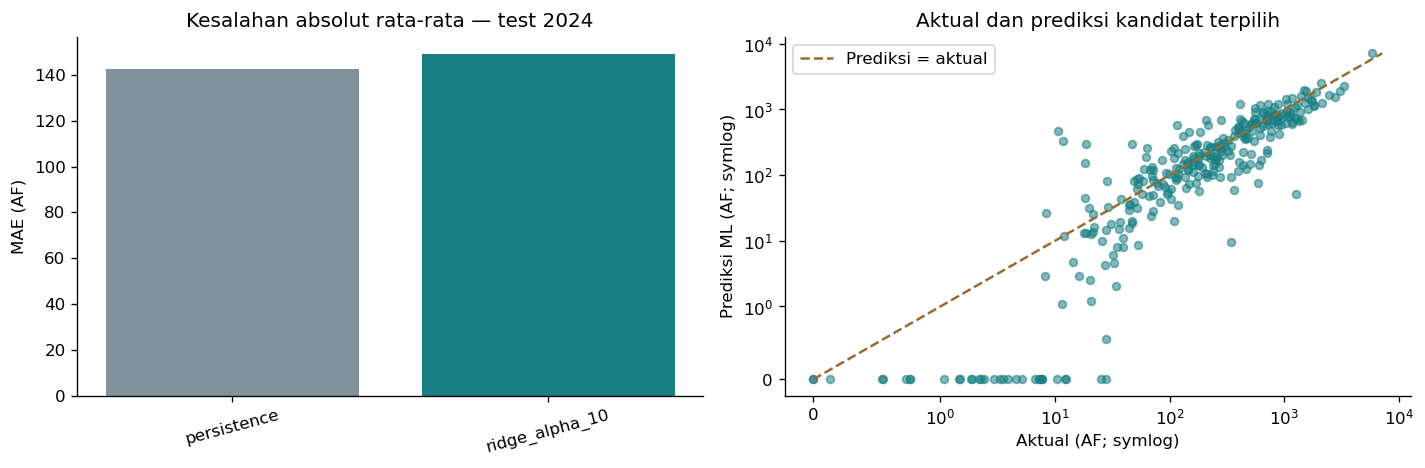

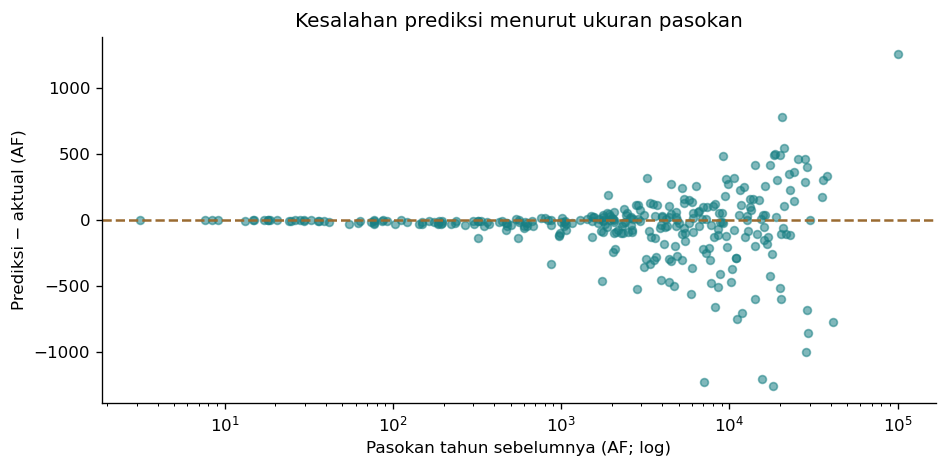

In [6]:
plt.rcParams.update({'figure.dpi':120,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(test_metrics.model,test_metrics.mae_af,color=['#81929D','#187F83'])
axes[0].set(ylabel='MAE (AF)',title='Kesalahan absolut rata-rata — test 2024')
axes[0].tick_params(axis='x',rotation=15)
axes[1].scatter(predictions.actual_real_losses_af,predictions.prediction_ml_af,alpha=.55,s=22,color='#187F83')
upper=float(max(predictions.actual_real_losses_af.max(),predictions.prediction_ml_af.max()))
axes[1].plot([0,upper],[0,upper],'--',color='#9A6B31',label='Prediksi = aktual')
axes[1].set_xscale('symlog',linthresh=1);axes[1].set_yscale('symlog',linthresh=1)
axes[1].set(xlabel='Aktual (AF; symlog)',ylabel='Prediksi ML (AF; symlog)',title='Aktual dan prediksi kandidat terpilih')
axes[1].legend()
fig.tight_layout();fig.savefig(output/'05_test_evaluation.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(8,4))
ax.scatter(predictions.water_supplied_af_t,predictions.error_ml_af,alpha=.55,s=22,color='#187F83')
ax.axhline(0,color='#9A6B31',linestyle='--');ax.set_xscale('log')
ax.set(xlabel='Pasokan tahun sebelumnya (AF; log)',ylabel='Prediksi − aktual (AF)',title='Kesalahan prediksi menurut ukuran pasokan')
fig.tight_layout();fig.savefig(output/'05_error_by_supply.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)


### 7. Menyimpan hasil untuk dashboard dan PPT
Saya menyimpan prediksi, metrik, keputusan pemilihan, serta model beserta urutan fitur dan aturan pemotongan prediksi negatif. Model yang disimpan dilatih sampai tahun target 2023; test 2024 tetap digunakan sebagai evaluasi akhir, bukan dimasukkan kembali untuk training.

File model hanya untuk eksperimen retrospektif. Pemakaian pada data baru perlu memastikan fitur, satuan, kualitas, dan waktu ketersediaannya sesuai. Dashboard berikutnya akan menampilkan hasil evaluasi ini bersama baseline; keberadaan file model tidak otomatis berarti layak digunakan secara operasional.


In [7]:
for filename,table in [
    ('05_validation_metrics.csv',validation_metrics),
    ('05_training_metrics.csv',training_metrics),
    ('05_validation_by_year.csv',validation_by_year),
    ('05_test_metrics.csv',test_metrics),
    ('05_test_predictions.csv',predictions),
    ('05_test_segments.csv',segment_metrics)]:
    table.to_csv(output/filename,index=False,encoding='utf-8-sig')
val_export=validation[['system_key','target_year',TARGET]].copy()
for name,p in val_predictions.items():val_export[name]=p
val_export.to_csv(output/'05_validation_predictions.csv',index=False,encoding='utf-8-sig')
versions={'python':platform.python_version(),'sklearn':sklearn.__version__,
          'pandas':pd.__version__,'numpy':np.__version__,'joblib':joblib.__version__}
bundle={'model':final_model,'model_name':best_ml,'features':FEATURES,'target':TARGET,
        'unit':'acre-feet','clip_predictions_at_zero':True,'baseline_feature':BASELINE,
        'trained_target_years':sorted(development.target_year.unique().tolist()),
        'versions':versions,'intended_use':'retrospective evaluation; publication timing unverified'}
model_path=model_dir/'water_loss_selected_ml.joblib'
joblib.dump(bundle,model_path)
# Hanya memuat file yang baru dibuat sendiri untuk memeriksa penyimpanan.
restored=joblib.load(model_path)
restored_p,_=predict_nonnegative(restored['model'],test[restored['features']])
assert np.allclose(restored_p,test_pred)
assert np.isclose(predictions.abs_error_ml_af.mean(),ml_test)
assert np.isclose(predictions.abs_error_baseline_af.mean(),base_test)
assert hashlib.sha256(source_path.read_bytes()).hexdigest()==config['input_sha256']

result={'selection':selection,'test_year':2024,'test_samples':len(test),
        'baseline_test_mae_af':base_test,'selected_ml_test_mae_af':ml_test,
        'test_mae_improvement_pct':improvement_pct,
        'size_cutpoints_af':cutpoints.tolist(),'versions':versions,
        'ml_better_on_validation':bool(ml_val<baseline_val),
        'ml_better_on_test':bool(ml_test<base_test),
        'operational_readiness_established':False,
        'input_hashes':{p.name:hashlib.sha256(p.read_bytes()).hexdigest()
                        for p in [ml_dir/'ml_config.json',*sorted(ml_dir.glob('water_loss_*.csv'))]}}
(output/'05_model_summary.json').write_text(json.dumps(result,indent=2),encoding='utf-8')
comparison='lebih rendah' if ml_test<base_test else ('sama' if ml_test==base_test else 'lebih tinggi')
summary=[
 '# Ringkasan modeling',
 f'- Kandidat ML terpilih berdasarkan validation: {best_ml}.',
 f'- MAE validation: baseline {baseline_val:.2f} AF; kandidat ML {ml_val:.2f} AF.',
 f'- Evaluasi test 2024: {len(test)} pasangan sistem-tahun.',
 f'- MAE test: baseline {base_test:.2f} AF; kandidat ML {ml_test:.2f} AF.',
 f'- MAE kandidat ML pada test {comparison} daripada baseline.',
 '- Kandidat dipilih sebelum test; hasil test tidak digunakan untuk memilih ulang model.',
 '', 'Batas interpretasi:',
 '- Hasil berasal dari satu tahun test pada sampel audit yang lolos cleaning.',
 '- Waktu publikasi dan revisi audit historis belum diverifikasi; ini bukan backtest operasional.',
 '- Sistem yang sama dapat muncul antartahun; hasil bukan bukti generalisasi ke seluruh sistem baru.',
 '- MAE global perlu dibaca bersama kesalahan menurut ukuran sistem dan RMSE.',
 '- Perbedaan numerik belum merupakan bukti signifikansi statistik atau manfaat operasional.',
 '', 'Hubungan dengan proyek data analis:',
 '- SQL dan EDA menjelaskan cakupan dan pola historis; ML menambah evaluasi prediksi terhadap baseline.',
 '- Dashboard harus menampilkan periode, ukuran sampel, baseline, dan keterbatasan ini.',
 '- Analisis SQL saat ini memakai SQLite lokal, bukan BigQuery.',
]
if improvement_pct is not None:summary.insert(5,f'- Perubahan MAE relatif terhadap baseline: {improvement_pct:+.2f}% (positif = MAE lebih kecil).')
if not (ml_val<baseline_val and ml_test<base_test):
    summary += ['', 'Catatan hasil: keunggulan ML belum konsisten pada validation dan test. Baseline tetap perlu ditonjolkan; jangan menyebut ML terbukti lebih unggul secara umum.']
summary_text='\n'.join(summary)
(output/'05_modeling_notes.md').write_text(summary_text,encoding='utf-8')
print(summary_text)
print('Model tersimpan:',model_path.relative_to(ROOT))
print('Selesai. Metrik, prediksi, grafik, dan keputusan eksperimen tersedia di outputs/modeling/.')


# Ringkasan modeling
- Kandidat ML terpilih berdasarkan validation: ridge_alpha_10.
- MAE validation: baseline 163.18 AF; kandidat ML 157.12 AF.
- Evaluasi test 2024: 307 pasangan sistem-tahun.
- MAE test: baseline 142.56 AF; kandidat ML 149.04 AF.
- Perubahan MAE relatif terhadap baseline: -4.54% (positif = MAE lebih kecil).
- MAE kandidat ML pada test lebih tinggi daripada baseline.
- Kandidat dipilih sebelum test; hasil test tidak digunakan untuk memilih ulang model.

Batas interpretasi:
- Hasil berasal dari satu tahun test pada sampel audit yang lolos cleaning.
- Waktu publikasi dan revisi audit historis belum diverifikasi; ini bukan backtest operasional.
- Sistem yang sama dapat muncul antartahun; hasil bukan bukti generalisasi ke seluruh sistem baru.
- MAE global perlu dibaca bersama kesalahan menurut ukuran sistem dan RMSE.
- Perbedaan numerik belum merupakan bukti signifikansi statistik atau manfaat operasional.

Hubungan dengan proyek data analis:
- SQL dan EDA menjelaskan cak

### Referensi metode dan langkah berikutnya
- [scikit-learn: common pitfalls dan data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [scikit-learn: RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html)

Setelah hasil diperiksa, dashboard diperbarui untuk menampilkan perbandingan baseline–ML dan kesalahan prediksi test. Insight SQL/EDA dan hasil ML disajikan sebagai dua bagian yang saling melengkapi dalam PPT. Tidak ada klaim scraping, BigQuery, atau prediksi operasional sebelum pekerjaan tersebut benar-benar dilakukan.
